# Stochastic simulations

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gstonge/csi4124-sys5110/blob/main/notebooks/stochastic-simulation.ipynb)
[![Open in JupyterLite](https://jupyterlite.rtfd.io/en/latest/_static/badge.svg)](https://www.gstonge.ca/csi4124-sys5110/lite/notebooks/index.html?path=stochastic-simulation.ipynb)

In the previous weeks, populations were described by continuous quantities that vary smoothly in time. Real populations are made of individuals: the state $x(t)$ is an integer, and it changes by discrete jumps when *events* (a birth, a death, ...) happen at random times. This notebook builds stochastic simulations of such population models, from the simplest one (births only) to the full predator-prey dynamics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Birth process

Each individual gives birth independently, at rate $\alpha$: in an infinitesimal time interval $\mathrm{dt}$, a given individual reproduces with probability $\alpha \, \mathrm{dt}$. With $x$ individuals, births therefore occur in the whole population at rate $\alpha x$, and each birth changes the state as $x \to x + 1$.

### Idea #1: an Euler-like method

Cut time into $M$ steps of length $h = T/M$ and, at each step, draw a birth with probability $\alpha x h$.

In [2]:
x = 5
x_traj = [x]
rng = np.random.default_rng(42)
T = 20
alpha = 0.2
M = 100
h = T/M
t = np.linspace(0, T, M+1)

In [3]:
for m in range(M):
    rate = alpha*x_traj[-1]
    prob = rate*h
    bern = 1 if rng.random() < prob else 0
    x += bern
    x_traj.append(x)

Text(0, 0.5, 'Number of prey')

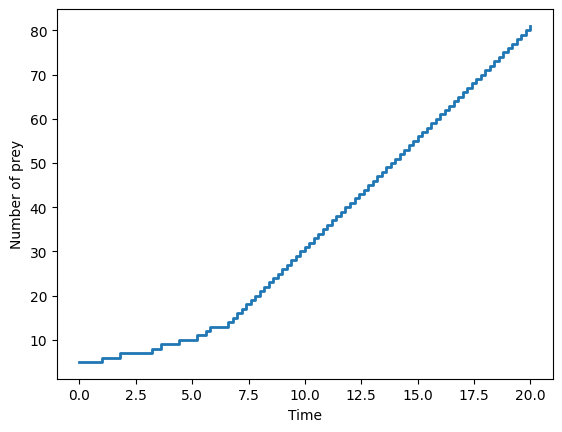

In [4]:
plt.step(t, x_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of prey')

### Idea #2: Jumping to the next event (Gillespie's direct method)

Rather than checking at every small step whether something happened, sample directly the time until the next event. When births occur at rate $\alpha x$, the waiting time $\tau$ to the next one is exponentially distributed with mean $1/(\alpha x)$; we jump to $t + \tau$ and apply the event.

In [5]:
x = 5
x_traj = [x]
rng = np.random.default_rng(42)
T = 20
alpha = 0.2
t = 0
t_traj = [t]

In [6]:
while t < T:
    tau = rng.exponential(scale=1/(alpha*x))
    t += tau
    x += 1
    t_traj.append(t)
    x_traj.append(x)

Text(0, 0.5, 'Number of prey')

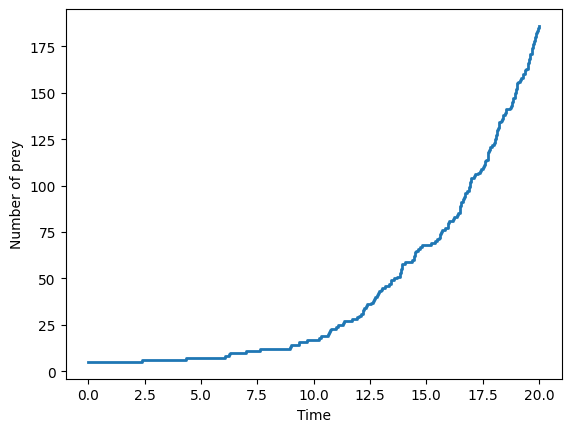

In [7]:
plt.step(t_traj, x_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of prey')

## Birth-death process

Now we have two competing processes: birth and death of entities. Each individual gives birth at rate $\alpha$ and dies at rate $\sigma$, so at the population level births ($x \to x+1$) occur at rate $\alpha x$ and deaths ($x \to x-1$) at rate $\sigma x$.

The next event happens after an exponential time with total rate $\alpha x + \sigma x$, and it is a birth with probability $\alpha x / (\alpha x + \sigma x)$. Note that $x = 0$ is now reachable. This is an *absorbing state*. Once the population is extinct, no event can happen anymore!

In [8]:
x = 5
x_traj = [x]
rng = np.random.default_rng(42)
T = 20
alpha = 0.3
sigma = 0.1
t = 0
t_traj = [t]

In [9]:
while t < T:
    if x == 0:
        break #extinction: no event can happen anymore
    #determine inter-event time
    total_rate = alpha*x + sigma*x
    tau = rng.exponential(scale=1/(total_rate))
    t += tau
    #now we determine which event happens
    prob_birth = alpha/(alpha + sigma)
    if rng.random() < prob_birth:
        x += 1
    else:
        x -= 1
    t_traj.append(t)
    x_traj.append(x)

Text(0, 0.5, 'Number of prey')

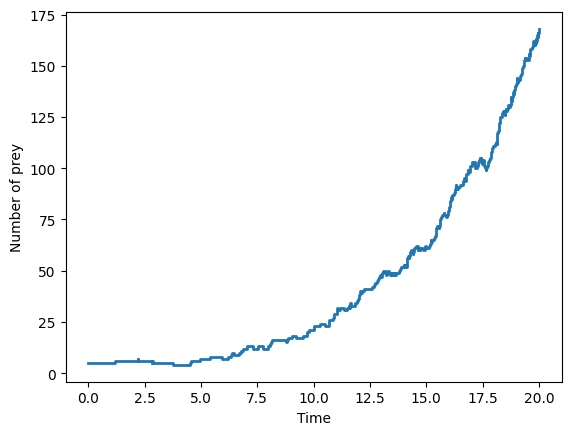

In [10]:
plt.step(t_traj, x_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of prey')

## Birth-death process with meteorites

On top of births and deaths, a meteorite occasionally hits the population. Meteorites fall at a constant rate $\mu$, independent of the population size, and each individual survives the impact with probability $1/2$: a meteorite changes the state as $x \to x - k$, with $k \sim \text{Binomial}(x, 1/2)$.

In [11]:
x = 5
x_traj = [x]
rng = np.random.default_rng(42)
T = 100
alpha = 0.3
sigma = 0.1
mu = 0.2
t = 0
t_traj = [t]

In [12]:
while t < T:
    #determine inter-event time
    total_rate = alpha*x + sigma*x + mu
    tau = rng.exponential(scale=1/(total_rate))
    t += tau
    #now we determine which event happens
    prob_birth = alpha*x/(alpha*x + sigma*x + mu)
    if rng.random() < prob_birth:
        x += 1
    else:
        prob_death = sigma*x/(sigma*x + mu)
        if rng.random() < prob_death:
            x -= 1
        else:
            #meteorite falls
            x -= rng.binomial(x,0.5)
    t_traj.append(t)
    x_traj.append(x)

Text(0, 0.5, 'Number of prey')

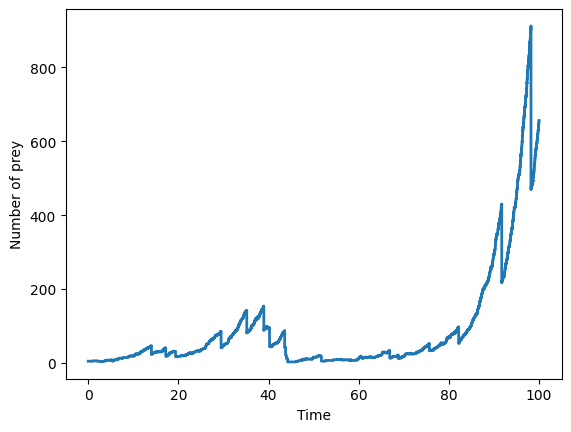

In [13]:
plt.step(t_traj, x_traj, where="post", lw=2)
plt.xlabel('Time')
plt.ylabel('Number of prey')

## Sampling multiple trajectories

A single trajectory is one realization of a stochastic process. To say anything about the process itself, we need to sample many independent trajectories and look at the ensemble.

In [14]:
x0 = 5
rng = np.random.default_rng(42)
T = 20
alpha = 0.3
sigma = 0.1
mu = 0.2
nb_samples = 100

In [15]:
def sample_process(x0,rng,T=T,alpha=alpha,sigma=sigma,mu=mu):
    #initialize
    x = x0*1
    t = 0
    t_traj = [t]
    x_traj = [x]
    
    #loop over next event
    while t < T:
        #determine inter-event time
        total_rate = alpha*x + sigma*x + mu
        tau = rng.exponential(scale=1/(total_rate))
        t += tau
        #now we determine which event happens
        prob_birth = alpha*x/(alpha*x + sigma*x + mu)
        if rng.random() < prob_birth:
            x += 1
        else:
            #we've eliminated birth event, we compare only death & meteorite rates
            prob_death = sigma*x/(sigma*x + mu)
            if rng.random() < prob_death:
                x -= 1
            else:
                #meteorite falls
                x -= rng.binomial(x,0.5)
        t_traj.append(t)
        x_traj.append(x)
    return t_traj, x_traj

Text(0, 0.5, 'Number of prey')

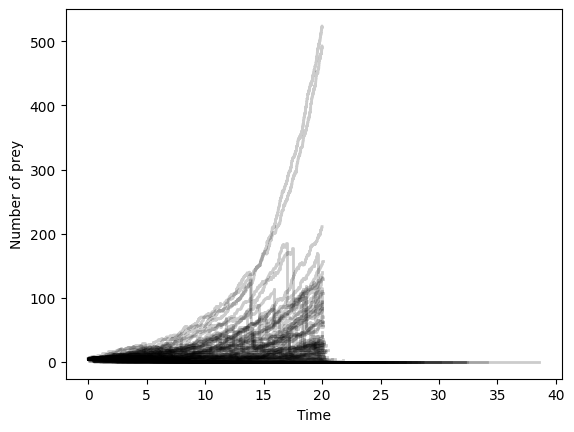

In [16]:
x_traj_samples = []
t_traj_samples = []
for _ in range(nb_samples):
    t_traj,x_traj = sample_process(x0,rng)
    x_traj_samples.append(x_traj)
    t_traj_samples.append(t_traj)
    plt.step(t_traj, x_traj, where="post", lw=2, color='k', alpha=0.2)
plt.xlabel('Time')
plt.ylabel('Number of prey')

### Fixed-time distributions and statistics

Fixing a time $t^*$ and reading the state of every trajectory at that time gives a sample of the random variable $x(t^*)$: its histogram estimates the distribution of $x(t^*)$, and its sample mean and standard deviation estimate those of the process.

In [17]:
t_chosen = 2
x_chosen_samples = []
for t_traj,x_traj in zip(t_traj_samples,x_traj_samples):
    index = np.searchsorted(t_traj,t_chosen, side='left')-1
    x_chosen_samples.append(x_traj[index])

mean = 6.09  std = 3.3409429806568087


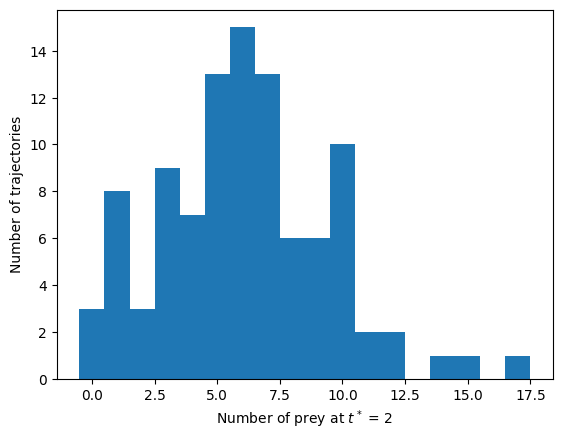

In [18]:
plt.hist(x_chosen_samples, bins=np.arange(max(x_chosen_samples)+2)-0.5)
plt.xlabel(f'Number of prey at $t^*$ = {t_chosen}')
plt.ylabel('Number of trajectories')
print('mean =', np.mean(x_chosen_samples), ' std =', np.std(x_chosen_samples))

## Exercise: Full predator-prey stochastic dynamics

Consider now the modelling of the number of prey and predators in a closed system, with birth and natural death of prey, predator natural death, and two types of "predation events":
1. A predator eats a prey — no predator is born;
2. A predator eats a prey — a new predator is born.

You should realize that the number of possible events is becoming large. A few suggestions to facilitate the implementation of the simulation procedure:
- define a (population-level) rate function for each event;
- define a state variation function for each event;
- put these functions in lists or dictionaries;
- use ```rng.choice``` to sample from a discrete distribution with specific probability (here each event is proportional to its rate).

Once you have your simulation algorithm, sample a few trajectories over sufficiently long time interval. Does the behavior look similar to the one of the deterministic model? Vary initial population sizes (for prey and predators) and the model parameters.

### Lynx and hare: real data

The Hudson's Bay Company traded furs in Canada for centuries, and its records of pelts give one of the most famous ecological time series: the number of snowshoe hares (prey) and Canada lynx (predators) trapped each year between 1845 and 1935, in thousands of pelts. The data below are those reproduced in E. P. Odum, *Fundamentals of Ecology* (Saunders, 1953).

In [19]:
year = np.arange(1845, 1936)
hare = np.array([19.58, 19.6, 19.61, 11.99, 28.04, 58.0, 74.6, 75.09, 88.48, 61.28,
                 74.67, 88.06, 68.51, 32.19, 12.64, 21.49, 30.35, 2.18, 152.65, 148.36,
                 85.81, 41.41, 14.75, 2.28, 5.91, 9.95, 10.44, 70.64, 50.12, 50.13,
                 101.25, 97.12, 86.51, 72.17, 38.32, 10.11, 7.74, 9.67, 43.12, 52.21,
                 134.85, 134.86, 103.79, 46.1, 15.03, 24.2, 41.65, 52.34, 53.78, 70.4,
                 85.81, 56.69, 16.59, 6.16, 2.3, 12.82, 4.72, 4.73, 37.22, 69.72,
                 57.78, 28.68, 23.37, 21.54, 26.34, 53.1, 68.48, 75.58, 57.92, 40.97,
                 24.95, 12.59, 4.97, 4.5, 11.21, 56.6, 69.63, 77.74, 80.53, 73.38,
                 36.93, 4.64, 2.54, 1.8, 2.39, 4.23, 19.52, 82.11, 89.76, 81.66,
                 15.76])
lynx = np.array([30.09, 45.15, 49.15, 39.52, 21.23, 8.42, 5.56, 5.08, 10.17, 19.6,
                 32.91, 34.38, 29.59, 21.3, 13.69, 7.65, 4.08, 4.09, 14.33, 38.22,
                 60.78, 70.77, 72.77, 42.68, 16.39, 9.83, 5.8, 5.26, 18.91, 30.95,
                 31.18, 46.34, 45.77, 44.15, 36.33, 12.03, 12.6, 18.34, 35.14, 43.77,
                 65.69, 79.35, 51.65, 32.59, 22.45, 16.16, 14.12, 20.38, 33.33, 46.0,
                 51.41, 46.43, 33.68, 18.01, 8.86, 7.13, 9.47, 14.86, 31.47, 60.57,
                 63.51, 54.7, 6.3, 3.41, 5.44, 11.65, 20.35, 32.88, 39.55, 43.36,
                 40.83, 30.36, 17.18, 6.82, 3.19, 3.52, 9.94, 20.3, 31.99, 42.36,
                 49.08, 53.99, 52.25, 37.7, 19.14, 6.98, 8.31, 16.01, 24.82, 29.7,
                 35.4])

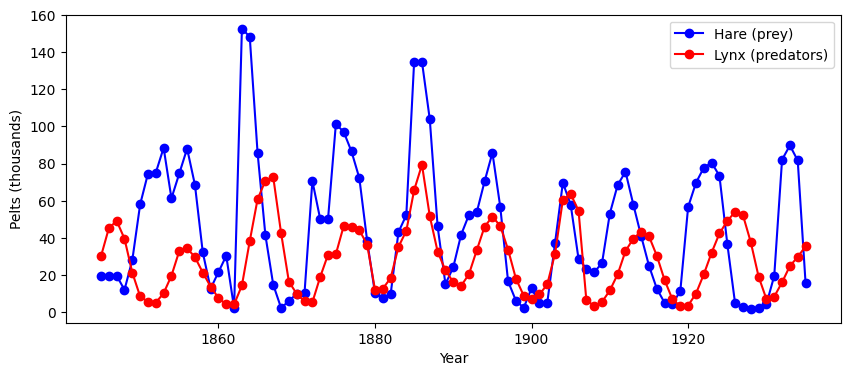

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(year, hare, 'o-', color='b', label='Hare (prey)')
ax.plot(year, lynx, 'o-', color='r', label='Lynx (predators)')
ax.set_xlabel('Year')
ax.set_ylabel('Pelts (thousands)')
ax.legend()

Both populations oscillate with a period of roughly ten years, and the lynx peaks tend to come shortly after the hare peaks.

Tune the parameters and the initial populations of your stochastic predator-prey model until its trajectories show a similar pattern. Compare the shapes, not the absolute numbers: the data count pelts, not animals.